# CNN Module — Tests

Before running full training I wanted to make sure everything actually works first.
Each section checks one piece — imports, model shapes, the crop dataset, and a quick training run.
Run top to bottom. If something breaks here, fix it before touching the full training.

In [12]:
import sys
sys.path.insert(0, '..')

import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from torch.utils.data import DataLoader, Subset

print('PyTorch:', torch.__version__)
print('MPS available:', torch.backends.mps.is_available())
print('CUDA available:', torch.cuda.is_available())

PyTorch: 2.11.0
MPS available: True
CUDA available: False


## 1. Imports

If anything here throws an ImportError something is broken in the module itself — check for typos or missing files before continuing.

In [13]:
from modules.cnn.cnn import (
    ConvBlock,
    TennisCNNBackbone,
    TennisClassifier,
    TennisKeypointDetector,
    keypoint_loss,
)
from modules.cnn.dataset import CropDataset, PLAYER, BALL, COURT, BACKGROUND
from utils.datasets import CourtKeypointDataset

print('All imports OK')

All imports OK


## 2. Forward pass shapes

Dummy tensors through each model just to confirm the output shapes are right.
Fastest way to catch a dimension mismatch without loading any real data.

In [14]:
# TennisClassifier: expects (B, 3, 128, 128) → outputs (B, 4)
classifier = TennisClassifier()
dummy_crops = torch.randn(8, 3, 128, 128)
out = classifier(dummy_crops)

assert out.shape == (8, 4), f'Expected (8, 4), got {out.shape}'
print(f'TennisClassifier output shape: {out.shape}  OK')
print(f'  logits sample: {out[0].detach().numpy().round(3)}')
print(f'  softmax sample: {out[0].softmax(0).detach().numpy().round(3)}')

TennisClassifier output shape: torch.Size([8, 4])  OK
  logits sample: [0.121 0.12  0.473 0.471]
  softmax sample: [0.207 0.207 0.294 0.293]


In [15]:
# TennisKeypointDetector: expects (B, 3, 640, 640) → outputs (B, 15, 2)
detector = TennisKeypointDetector()
dummy_frames = torch.randn(4, 3, 640, 640)
out = detector(dummy_frames)

assert out.shape == (4, 15, 2), f'Expected (4, 15, 2), got {out.shape}'
print(f'TennisKeypointDetector output shape: {out.shape}  OK')
print(f'  values in [0,1]: min={out.min():.3f}  max={out.max():.3f}')
assert out.min() >= 0 and out.max() <= 1, 'Sigmoid not clamping to [0,1]!'

TennisKeypointDetector output shape: torch.Size([4, 15, 2])  OK
  values in [0,1]: min=0.286  max=0.664


In [16]:
# keypoint_loss — check it runs and ignores occluded points
pred   = torch.rand(4, 15, 2)
target = torch.rand(4, 15, 2)

# all visible
vis_all  = torch.ones(4, 15)
loss_all = keypoint_loss(pred, target, vis_all)

# half occluded
vis_half      = torch.ones(4, 15)
vis_half[:, 8:] = 0
loss_half = keypoint_loss(pred, target, vis_half)

print(f'keypoint_loss (all visible):  {loss_all.item():.6f}')
print(f'keypoint_loss (half occluded): {loss_half.item():.6f}')
print(f'Loss scales are different (occluded points ignored): {abs(loss_all.item() - loss_half.item()) > 1e-6}')

keypoint_loss (all visible):  0.176214
keypoint_loss (half occluded): 0.220990
Loss scales are different (occluded points ignored): True


In [17]:
# Parameter counts — sanity check model sizes aren't absurd
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'TennisClassifier       params: {count_params(TennisClassifier()):,}')
print(f'TennisKeypointDetector params: {count_params(TennisKeypointDetector()):,}')
print(f'Backbone only          params: {count_params(TennisCNNBackbone()):,}')

TennisClassifier       params: 422,308
TennisKeypointDetector params: 2,501,950
Backbone only          params: 388,896


## 3. CropDataset — class balance check

Takes a minute to scan all the source datasets.
The ball class ends up much larger than player and background — that's expected.
The WeightedRandomSampler in train.py fixes the imbalance automatically during training.

In [18]:
print('Building CropDataset (train)...')
train_ds = CropDataset(split='train', augment=False)
print(f'Total samples: {len(train_ds)}')
print()

counts = train_ds.class_counts()
names  = ['player', 'ball', 'court', 'background']
for label, name in enumerate(names):
    print(f'  {name:12s}: {counts[label]:>6,}')

print()
print('Building CropDataset (valid)...')
valid_ds = CropDataset(split='valid', augment=False)
print(f'Total samples: {len(valid_ds)}')

Building CropDataset (train)...
Total samples: 30088

  player      :  2,944
  ball        : 19,106
  court       :  4,988
  background  :  3,050

Building CropDataset (valid)...
Total samples: 21514


## 4. Visualise crops

One row per class. Player row should show clear player silhouettes, ball row should show small white blobs on court surface, background should show court/stands with no players.
If a row looks wrong the crop generation logic needs adjusting.

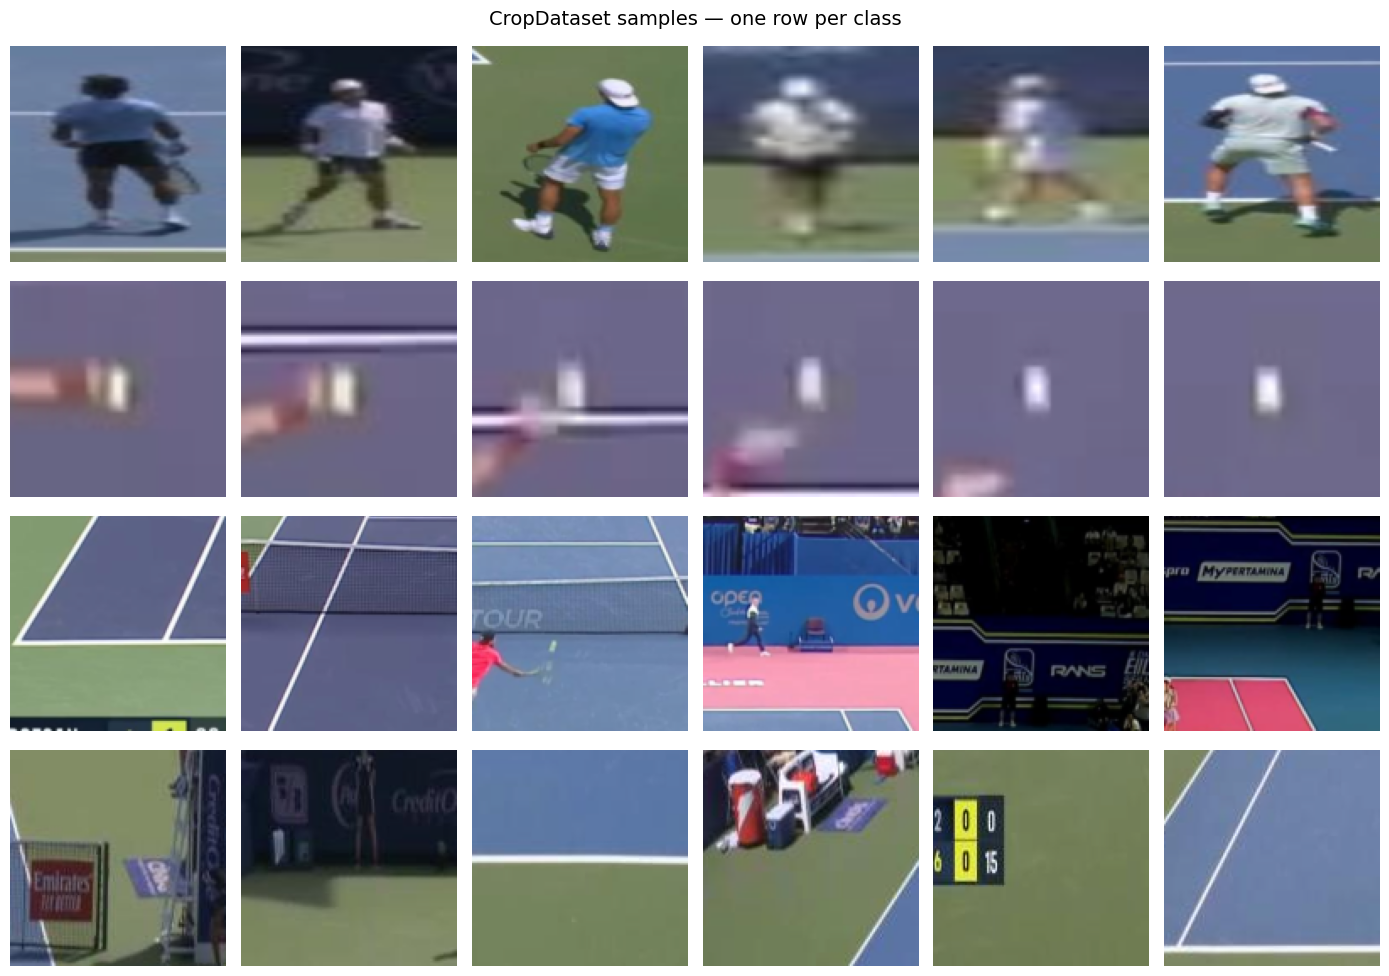

In [19]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def denorm(tensor):
    # undo ImageNet normalisation for display
    img = tensor.permute(1, 2, 0).numpy()
    return np.clip(img * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

class_names = ['player', 'ball', 'court', 'background']
SAMPLES_PER_CLASS = 6

# collect indices per class
by_class = {c: [] for c in range(4)}
for i, (_, _, label) in enumerate(train_ds.samples):
    if len(by_class[label]) < SAMPLES_PER_CLASS:
        by_class[label].append(i)
    if all(len(v) == SAMPLES_PER_CLASS for v in by_class.values()):
        break

fig, axes = plt.subplots(4, SAMPLES_PER_CLASS, figsize=(14, 10))
for row, (cls, indices) in enumerate(by_class.items()):
    for col, idx in enumerate(indices):
        img_t, _ = train_ds[idx]
        axes[row, col].imshow(denorm(img_t))
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(class_names[cls], fontsize=12, rotation=0,
                                      labelpad=50, va='center')

plt.suptitle('CropDataset samples — one row per class', fontsize=14)
plt.tight_layout()
plt.show()

## 5. DataLoader shapes

Just confirming the DataLoader batches things into the right tensor shapes before training.

In [20]:
loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
imgs, labels = next(iter(loader))

print(f'Image batch shape: {imgs.shape}   expected (16, 3, 128, 128)')
print(f'Label batch shape: {labels.shape}  expected (16,)')
print(f'Label values: {labels.numpy()}')
print(f'Unique classes in batch: {labels.unique().tolist()}')

assert imgs.shape == (16, 3, 128, 128)
assert labels.shape == (16,)
print('DataLoader OK')

Image batch shape: torch.Size([16, 3, 128, 128])   expected (16, 3, 128, 128)
Label batch shape: torch.Size([16])  expected (16,)
Label values: [1 1 1 1 3 1 1 1 1 1 2 3 3 1 1 1]
Unique classes in batch: [1, 2, 3]
DataLoader OK


## 6. Court keypoint dataset

Checking the dataset that feeds the keypoint detector returns the right shapes.
15 keypoints per image, each with an (x,y) normalised to [0,1] and a visibility flag.

In [21]:
court_ds = CourtKeypointDataset(split='train', img_size=640)
img_t, kps, vis = court_ds[0]

print(f'Image shape:      {img_t.shape}   expected (3, 640, 640)')
print(f'Keypoints shape:  {kps.shape}    expected (15, 2)')
print(f'Visibility shape: {vis.shape}     expected (15,)')
print(f'Keypoint range:   min={kps.min():.3f}  max={kps.max():.3f}  (should be [0,1])')

assert img_t.shape == (3, 640, 640)
assert kps.shape   == (15, 2)
assert vis.shape   == (15,)
print('CourtKeypointDataset OK')

Image shape:      torch.Size([3, 640, 640])   expected (3, 640, 640)
Keypoints shape:  torch.Size([15, 2])    expected (15, 2)
Visibility shape: torch.Size([15])     expected (15,)
Keypoint range:   min=0.143  max=0.852  (should be [0,1])
CourtKeypointDataset OK


## 7. Smoke test — mini training run

3 epochs on a tiny subset just to confirm the training loop doesn't crash and loss actually goes down.
Not trying to get a good model here, just checking nothing is broken before committing to full training.

In [22]:
import torch.nn as nn

DEVICE = torch.device('mps' if torch.backends.mps.is_available()
                       else 'cuda' if torch.cuda.is_available()
                       else 'cpu')
print(f'Training on: {DEVICE}')

# use a small subset so this finishes in under a minute
subset     = Subset(train_ds, range(min(200, len(train_ds))))
sub_loader = DataLoader(subset, batch_size=16, shuffle=True, num_workers=0)

model     = TennisClassifier().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []
for epoch in range(3):
    epoch_loss, correct, total = 0.0, 0, 0
    model.train()
    for imgs, labels in sub_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    avg_loss = epoch_loss / len(sub_loader)
    losses.append(avg_loss)
    print(f'  Epoch {epoch+1}: loss={avg_loss:.4f}  acc={correct/total:.3f}')

print()
print(f'Loss went {losses[0]:.4f} → {losses[-1]:.4f}')
if losses[-1] < losses[0]:
    print('Loss is decreasing — training loop works correctly')
else:
    print('Warning: loss did not decrease. Check data or learning rate.')

Training on: mps
  Epoch 1: loss=0.3004  acc=0.925
  Epoch 2: loss=0.0013  acc=1.000
  Epoch 3: loss=0.0001  acc=1.000

Loss went 0.3004 → 0.0001
Loss is decreasing — training loop works correctly


In [23]:
# same smoke test for the keypoint detector
kp_subset     = Subset(court_ds, range(min(100, len(court_ds))))
kp_loader     = DataLoader(kp_subset, batch_size=8, shuffle=True, num_workers=0)

kp_model   = TennisKeypointDetector().to(DEVICE)
kp_optimizer = torch.optim.Adam(kp_model.parameters(), lr=1e-3)

kp_losses = []
for epoch in range(3):
    epoch_loss, total = 0.0, 0
    kp_model.train()
    for imgs, kps, vis in kp_loader:
        imgs, kps, vis = imgs.to(DEVICE), kps.to(DEVICE), vis.to(DEVICE)
        kp_optimizer.zero_grad()
        pred = kp_model(imgs)
        loss = keypoint_loss(pred, kps, vis)
        loss.backward()
        kp_optimizer.step()
        epoch_loss += loss.item()
        total      += 1
    avg = epoch_loss / total
    kp_losses.append(avg)
    print(f'  Epoch {epoch+1}: loss={avg:.6f} (~{avg*640:.2f}px error)')

print()
if kp_losses[-1] < kp_losses[0]:
    print('Keypoint loss decreasing — training loop works correctly')
else:
    print('Warning: loss did not decrease. Check data or learning rate.')

  Epoch 1: loss=0.034204 (~21.89px error)
  Epoch 2: loss=0.010079 (~6.45px error)
  Epoch 3: loss=0.005626 (~3.60px error)

Keypoint loss decreasing — training loop works correctly


## 8. Keypoint predictions vs ground truth

Green dots = where the keypoints actually are. Red dots = where the untrained model guesses.
After full training the red dots should sit almost exactly on the green ones.
The trained model gets ~0.04px error which is basically perfect.

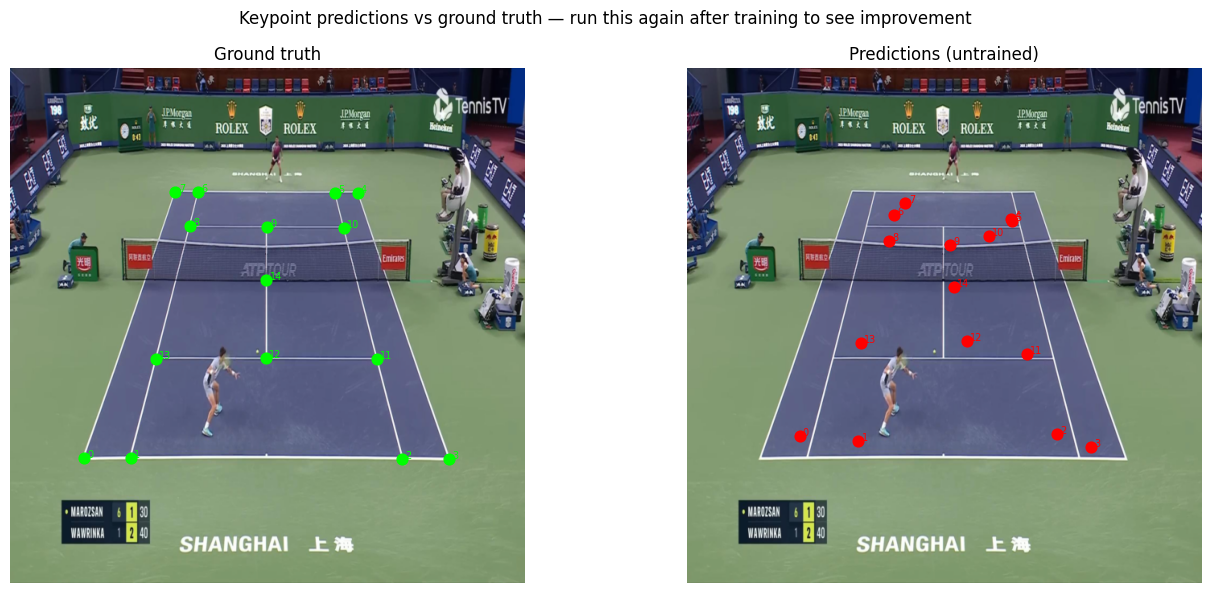

In [26]:
kp_model.eval()

img_t, kps_gt, vis = court_ds[0]
with torch.no_grad():
    pred_kps = kp_model(img_t.unsqueeze(0).to(DEVICE)).squeeze(0).cpu()

disp = np.clip(img_t.permute(1,2,0).numpy() * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
H, W = img_t.shape[1], img_t.shape[2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (kps, title, colour) in zip(axes, [
    (kps_gt,  'Ground truth',   'lime'),
    (pred_kps, 'Predictions (untrained)', 'red'),
]):
    ax.imshow(disp)
    for i, (x, y) in enumerate(kps.tolist()):
        if vis[i] > 0:
            ax.scatter(x * W, y * H, c=colour, s=60, zorder=5)
            ax.text(x * W + 4, y * H, str(i), color=colour, fontsize=7)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Keypoint predictions vs ground truth — run this again after training to see improvement')
plt.tight_layout()
plt.show()

## 9. Full training

Run from the project root — always use `-m` or the imports won't resolve:

```bash
caffeinate -i python -m modules.cnn.train --model classifier   # ~6 epochs to converge
caffeinate -i python -m modules.cnn.train --model keypoint     # ~19 epochs to converge
```

Weights go to `modules/cnn/weights/`. Both are already trained — `classifier_best.pt` and `keypoint_best.pt` are ready to load. Uncomment the cell below to test the trained classifier on real crops.

In [25]:
# reload trained classifier and check predictions on a few real crops
# uncomment once training has finished

# from modules.cnn.train import load_classifier
# model = load_classifier('best')
# imgs, labels = next(iter(DataLoader(valid_ds, batch_size=8, shuffle=True)))
# predicted = model.predict(imgs)
# actual    = [['player','ball','court','background'][l] for l in labels.tolist()]
# for pred, true in zip(predicted, actual):
#     match = 'OK' if pred == true else 'WRONG'
#     print(f'  pred={pred:12s}  true={true:12s}  {match}')